## PathVQA — CNN + BiLSTM Late-Fusion Baseline

Organized workflow for dataset exploration, preprocessing, original 30-epoch training, checkpoint restoration, and optional fine-tuning.

**Important:** In a new Kaggle session, run the setup sections, then **skip the original 30-epoch training section** and proceed to checkpoint restoration and fine-tuning.

### Execution guide (Kaggle)

**Purpose.** This notebook implements a scratch-trained CNN + bidirectional LSTM with separate yes/no and 1,000-class open-answer heads. It also documents lower-learning-rate fine-tuning and a separate exploratory 2,000-class run.

**Environment.** Run in a Kaggle Notebook with Internet enabled for the initial Hugging Face dataset download, and enable a GPU if available. The first code cell installs `datasets`, `transformers`, `pillow`, `matplotlib`, and `pandas`. Other imports used below include `torch`, `numpy`, `tqdm`, and standard Python modules; these are typically present in Kaggle's Python image. The dataset is `flaviagiammarino/path-vqa`.

**Fresh run:** execute Sections 1–3 and 5–8 in order, including the image-overlap diagnostic in Section 2. Section 4 is intended for *resumed* sessions and is not needed to construct a new vocabulary from cleaned training data. Then run Sections 9–11 to inspect the baseline and fine-tune it. Section 12 is optional and is a separate 2,000-class experiment.

**Resume run:** attach the Kaggle dataset containing your saved `.pth` and history files; execute data loading, overlap detection and cleaning, Section 4 to restore vocabulary mappings, Sections 5–7 to define model/functions, then Section 9 to load the original best checkpoint before Section 10. Skip Section 8 to avoid retraining. Existing checkpoint names and paths are not changed in this documented version.

**Important:** Some diagnostic and resume cells assume that files or overlap hashes exist. Follow the relevant execution path and check printed paths; this documentation does not modify the executable code. Training can take substantial GPU time. The final held-out test comparison is performed in the separate all-model evaluation notebook, not here.

## 1. Environment and Dataset Loading

In [1]:

!pip install -q datasets transformers pillow matplotlib pandas

In [2]:
# Load the PathVQA dataset and inspect its available splits.

from datasets import load_dataset

dataset = load_dataset("flaviagiammarino/path-vqa")

print(dataset)


README.md:   0%|          | 0.00/4.29k [00:00<?, ?B/s]

data/train-00000-of-00007-f2d0e9ef9f022d(…): reconstructing file:   0%|          |  0.00B / 42.8MB            

data/train-00000-of-00007-f2d0e9ef9f022d(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-47d8e0220bf6c9(…): reconstructing file:   0%|          |  0.00B / 81.0MB            

data/train-00001-of-00007-47d8e0220bf6c9(…): downloading bytes:           |  0.00B            

data/train-00002-of-00007-7fb5037c4c5da7(…): reconstructing file:   0%|          |  0.00B /  104MB            

... (21 outputs left out)

Generating train split:   0%|          | 0/19654 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/6259 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6719 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'question', 'answer'],
        num_rows: 19654
    })
    validation: Dataset({
        features: ['image', 'question', 'answer'],
        num_rows: 6259
    })
    test: Dataset({
        features: ['image', 'question', 'answer'],
        num_rows: 6719
    })
})


Question: where are liver stem cells (oval cells) located?
Answer: in the canals of hering


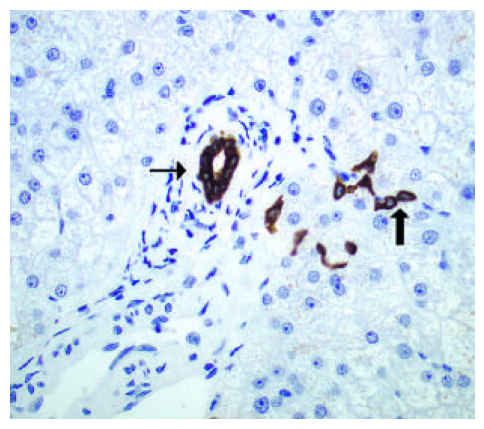

In [3]:

import matplotlib.pyplot as plt

sample = dataset["train"][0]

print("Question:", sample["question"])
print("Answer:", sample["answer"])

plt.figure(figsize=(6, 6))
plt.imshow(sample["image"].convert("RGB"))
plt.axis("off")
plt.show()


In [4]:

for split in dataset:
    print(f"{split}: {len(dataset[split])} samples")


train: 19654 samples
validation: 6259 samples
test: 6719 samples


## 2. Dataset Exploration and Diagnostics

Exploratory analysis only. You can skip this section when restarting a session to fine-tune.

Answer Type Distribution:
Open-ended: 9903
Closed-ended: 9751


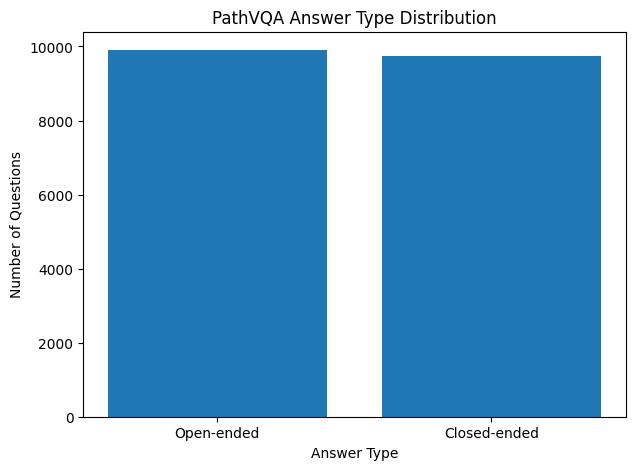

In [5]:
# Summarize answer frequencies to understand class imbalance before training.

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# Use training data only
train_data = dataset["train"]

questions = [str(q).lower().strip()
             for q in train_data["question"]]

answers = [str(a).lower().strip()
           for a in train_data["answer"]]

# Classify answers
def get_answer_type(answer):
    if answer in ["yes", "no"]:
        return "Closed-ended"
    return "Open-ended"

answer_types = [get_answer_type(a) for a in answers]

# Count each type
type_counts = Counter(answer_types)

print("Answer Type Distribution:")
for key, value in type_counts.items():
    print(f"{key}: {value}")

# Plot
plt.figure(figsize=(7, 5))
plt.bar(type_counts.keys(), type_counts.values())
plt.title("PathVQA Answer Type Distribution")
plt.xlabel("Answer Type")
plt.ylabel("Number of Questions")
plt.show()


Question Category Distribution:
Yes/No Form: 9749
What: 8040
Where: 1315
How: 427
Why: 71
When: 30
Other: 15
Whose: 5
Who: 2


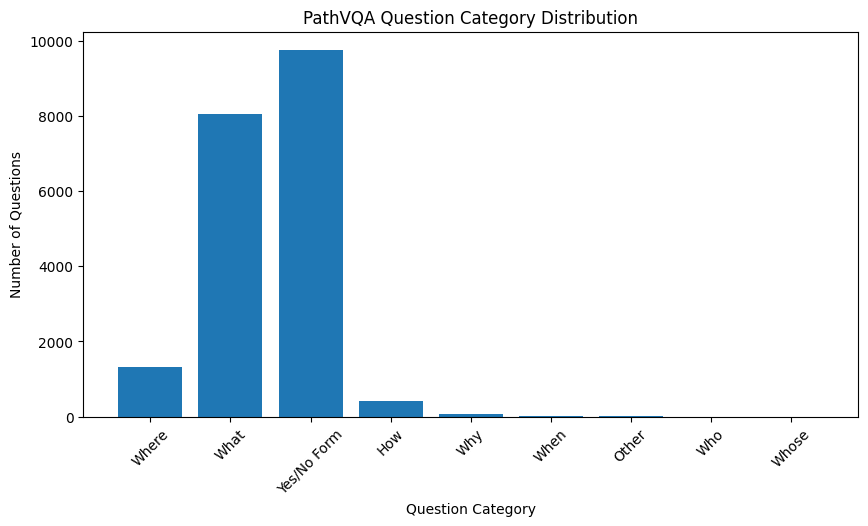

In [6]:
# Group question patterns for exploratory dataset analysis.

def get_question_category(question):
    question = question.lower().strip()
    words = question.split()

    if not words:
        return "Other"

    first = words[0]

    if first in ["what", "where", "when", "why",
                 "how", "which", "who", "whose"]:
        return first.capitalize()

    if first in ["is", "are", "was", "were", "do",
                 "does", "did", "can", "could",
                 "has", "have", "had", "will",
                 "would", "should"]:
        return "Yes/No Form"

    return "Other"

categories = [get_question_category(q) for q in questions]

category_counts = Counter(categories)

print("Question Category Distribution:")
for category, count in category_counts.most_common():
    print(f"{category}: {count}")

# Visualization
plt.figure(figsize=(10, 5))
plt.bar(category_counts.keys(), category_counts.values())
plt.title("PathVQA Question Category Distribution")
plt.xlabel("Question Category")
plt.ylabel("Number of Questions")
plt.xticks(rotation=45)
plt.show()


In [7]:

answer_counts = Counter(answers)

print("Total training samples:", len(answers))
print("Unique answers:", len(answer_counts))

print("\nTop 20 Most Frequent Answers:")
for answer, count in answer_counts.most_common(20):
    print(f"{answer}: {count}")

# Vocabulary coverage
total = len(answers)

for k in [100, 500, 1000, 2000]:
    top_answers = answer_counts.most_common(k)
    covered = sum(count for _, count in top_answers)

    print(f"Top {k} answers cover "
          f"{covered / total * 100:.2f}% of training samples")


Total training samples: 19654
Unique answers: 3225

Top 20 Most Frequent Answers:
yes: 5378
no: 4373
oral: 370
cardiovascular: 308
hematologic: 266
gastrointestinal: 264
endocrine: 250
lung: 208
hepatobiliary: 193
nervous: 178
female reproductive: 176
vasculature: 161
urinary: 159
liver: 153
spleen: 149
heart: 144
gastrointestinal system: 132
respiratory: 127
endocrine system: 126
brain: 116
Top 100 answers cover 77.60% of training samples
Top 500 answers cover 84.70% of training samples
Top 1000 answers cover 88.68% of training samples
Top 2000 answers cover 93.77% of training samples


In [8]:

from collections import Counter

# Separate open-ended answers
def normalize_answer(answer):
    return str(answer).lower().strip()

train_open = [
    normalize_answer(a)
    for a in dataset["train"]["answer"]
    if normalize_answer(a) not in ["yes", "no"]
]

val_open = [
    normalize_answer(a)
    for a in dataset["validation"]["answer"]
    if normalize_answer(a) not in ["yes", "no"]
]

# Count training answers
answer_counts = Counter(train_open)

print("Training open-ended samples:", len(train_open))
print("Validation open-ended samples:", len(val_open))
print("Unique training open-ended answers:", len(answer_counts))

print("\nVocabulary Coverage:")

for k in [100, 500, 1000, 2000, 3223]:
    vocab = set(
        answer for answer, count
        in answer_counts.most_common(k)
    )

    train_coverage = sum(
        a in vocab for a in train_open
    ) / len(train_open)

    val_coverage = sum(
        a in vocab for a in val_open
    ) / len(val_open)

    print(
        f"Top {k}: "
        f"Train={train_coverage:.2%}, "
        f"Validation={val_coverage:.2%}"
    )


Training open-ended samples: 9903
Validation open-ended samples: 3134
Unique training open-ended answers: 3223

Vocabulary Coverage:
Top 100: Train=55.70%, Validation=55.46%
Top 500: Train=69.68%, Validation=64.20%
Top 1000: Train=77.55%, Validation=66.56%
Top 2000: Train=87.65%, Validation=69.24%
Top 3223: Train=100.00%, Validation=71.28%


In [9]:

from collections import Counter
import numpy as np

image_sizes = []

for sample in dataset["train"]:
    image_sizes.append(sample["image"].size)

widths = [size[0] for size in image_sizes]
heights = [size[1] for size in image_sizes]

print("Minimum width:", min(widths))
print("Maximum width:", max(widths))
print("Minimum height:", min(heights))
print("Maximum height:", max(heights))

print("Average width:", np.mean(widths))
print("Average height:", np.mean(heights))

print("\nMost common image sizes:")
for size, count in Counter(image_sizes).most_common(10):
    print(size, count)


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Minimum width: 144
Maximum width: 1544
Minimum height: 144
Maximum height: 1025
Average width: 750.0096163630812
Average height: 509.67640175027987

Most common image sizes:
(792, 528) 8577
(768, 512) 1187
(792, 518) 598
(792, 524) 520
(792, 526) 401
(792, 531) 338
(792, 525) 266
(792, 527) 264
(792, 529) 255
(792, 532) 228


Minimum length: 2
Maximum length: 37
Average length: 6.258522438180523
Median length: 5.0
95th percentile: 16.0
99th percentile: 23.0


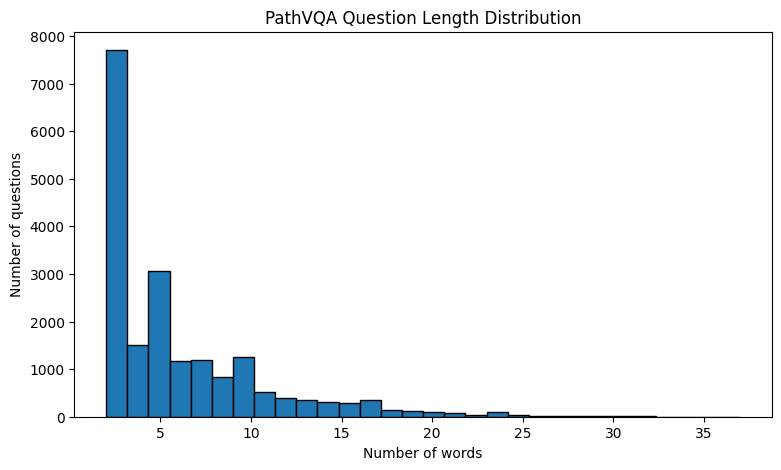

In [10]:

import numpy as np
import matplotlib.pyplot as plt

question_lengths = [
    len(q.split())
    for q in dataset["train"]["question"]
]

print("Minimum length:", min(question_lengths))
print("Maximum length:", max(question_lengths))
print("Average length:", np.mean(question_lengths))
print("Median length:", np.median(question_lengths))
print("95th percentile:", np.percentile(question_lengths, 95))
print("99th percentile:", np.percentile(question_lengths, 99))

plt.figure(figsize=(9, 5))
plt.hist(question_lengths, bins=30, edgecolor="black")
plt.xlabel("Number of words")
plt.ylabel("Number of questions")
plt.title("PathVQA Question Length Distribution")
plt.show()


In [11]:
# Hash decoded image pixels to detect exact image overlap across splits.

import hashlib
from collections import defaultdict

def image_hash(image):
    # Hash decoded RGB pixels and dimensions
    image = image.convert("RGB")
    h = hashlib.sha256()
    h.update(str(image.size).encode())
    h.update(image.tobytes())
    return h.hexdigest()

split_hashes = {}

for split in ["train", "validation", "test"]:
    hashes = set()

    for sample in dataset[split]:
        hashes.add(image_hash(sample["image"]))

    split_hashes[split] = hashes

    print(
        f"{split}: {len(hashes)} unique images"
    )

print("\nIdentical images across splits:")

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = split_hashes[a] & split_hashes[b]

    print(f"{a} vs {b}: {len(overlap)}")


train: 2599 unique images
validation: 832 unique images
test: 858 unique images

Identical images across splits:
train vs validation: 1
train vs test: 0
validation vs test: 0


In [12]:

train_answer_set = set(train_open)

unseen_answers = [
    a for a in val_open
    if a not in train_answer_set
]

print("Unseen validation answers:", len(unseen_answers))
print("Percentage:", round(
    100 * len(unseen_answers) / len(val_open), 2
))

print("\nExamples of unseen answers:")
for answer in unseen_answers[:20]:
    print("-", answer)


Unseen validation answers: 900
Percentage: 28.72

Examples of unseen answers:
- predominantly lymphocytic infiltrate
- wavy nuclei
- peritoneal carcinomatosis
- by predominantly lymphocytic infiltrate
- due to metastatic carcinoma breast primary i think
- bowel in situ with diffuse thickening of peritoneal surfaces due to metastatic carcinoma breast primary i think
- with diffuse thickening of peritoneal surfaces due to metastatic carcinoma breast primary i think
- during life large lesion
- a photo taken during life large lesion
- a photo
- during life large lesion
- fixed tissue typical appearance of tuberculous peritonitis except for color being off a bit
- close-up view of metastatic lesions color not the best papillary serous adenocarcinoma of ovary
- opened abdomen with ischemic appearing intestines
- by neoplastic adhesions good but not the best ovarian papillary adenocarcinoma
- a very close-up view of typical gross lesions
- eccentric lesion
- massive node enlargement like a l

### Data cleaning and vocabulary decisions

The split-overlap diagnostic hashes decoded RGB image pixels and dimensions. Training records whose image hashes overlap validation are removed from the *training* split only; validation is retained unchanged. The overlap-inspection cell immediately below assumes at least one overlap exists and may raise `StopIteration` on datasets with none. This is a diagnostic limitation, not a training-model change.

Questions are lowercased, stripped and tokenized into words and punctuation; sequences are capped at 32 tokens. Word and open-answer dictionaries are derived from the cleaned training data to avoid using validation answers to define output classes. Open-ended predictions are restricted to the 1,000 most frequent training answers, so out-of-vocabulary reference answers cannot be predicted exactly.

## 3. Cleaning, Tokenization, and Answer Vocabulary

Run these cells in order. The image-overlap check from Section 2 is required for the cleaning cell.

In [13]:
# Inspect one overlapping image as a data-leakage diagnostic.

# Find the overlapping image
overlapping_hash = next(iter(
    split_hashes["train"] & split_hashes["validation"]
))

for split in ["train", "validation"]:
    print(f"\n{split.upper()} SAMPLES")

    matches = []

    for i, sample in enumerate(dataset[split]):
        if image_hash(sample["image"]) == overlapping_hash:
            matches.append(i)

    print("Number of matching QA pairs:", len(matches))

    for i in matches[:10]:
        sample = dataset[split][i]
        print("Index:", i)
        print("Question:", sample["question"])
        print("Answer:", sample["answer"])
        print()



TRAIN SAMPLES
Number of matching QA pairs: 6
Index: 11821
Question: what are present?
Answer: several characteristic schiller-duval bodies

Index: 11823
Question: are several characteristic schiller-duval bodies present?
Answer: yes

Index: 11824
Question: what shows intra - and extracellular hyaline globules?
Answer: specimen of the uterus

Index: 11825
Question: what does inset show?
Answer: intra- and extracellular hyaline globules

Index: 11826
Question: does inset show intra - and extracellular hyaline globules?
Answer: yes

Index: 11827
Question: does epra bacilli in ll seen in fite-faraco show intra - and extracellular hyaline globules?
Answer: no


VALIDATION SAMPLES
Number of matching QA pairs: 6
Index: 6099
Question: are several characteristic schiller-duval bodies present?
Answer: yes

Index: 6100
Question: are serpiginous ulcers, some deep fissures and swollen intervening surviving mucosa giving 'cobblestone appearance ', present?
Answer: no

Index: 6101
Question: what sho

In [14]:
# Build the training-only question vocabulary and answer mappings.

import re
from collections import Counter

MAX_QUESTION_LENGTH = 32

def tokenize(text):
    text = str(text).lower().strip()
    return re.findall(r"\w+|[^\w\s]", text)

# Build vocabulary from training questions only
word_counts = Counter()

for question in dataset["train"]["question"]:
    word_counts.update(tokenize(question))

word2idx = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in word_counts.items():
    if word not in word2idx:
        word2idx[word] = len(word2idx)

print("Question vocabulary size:", len(word2idx))

def encode_question(question):
    tokens = tokenize(question)

    ids = [
        word2idx.get(token, word2idx["<UNK>"])
        for token in tokens
    ]

    ids = ids[:MAX_QUESTION_LENGTH]

    ids += [word2idx["<PAD>"]] * (
        MAX_QUESTION_LENGTH - len(ids)
    )

    return ids

# Test encoding
sample_question = dataset["train"][0]["question"]

encoded = encode_question(sample_question)

print("\nOriginal question:", sample_question)
print("Encoded question:", encoded)
print("Encoded length:", len(encoded))


Question vocabulary size: 3975

Original question: where are liver stem cells (oval cells) located?
Encoded question: [2, 3, 4, 5, 6, 7, 8, 6, 9, 10, 11, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Encoded length: 32


In [15]:
# Remove overlapping training records while keeping validation unchanged.

# Identify training samples with overlapping images
overlap_hashes = (
    split_hashes["train"] & split_hashes["validation"]
)

# Keep only training samples without overlap
keep_indices = []

for i, sample in enumerate(dataset["train"]):
    if image_hash(sample["image"]) not in overlap_hashes:
        keep_indices.append(i)

# Create cleaned dataset
clean_train = dataset["train"].select(keep_indices)

print("Original training samples:", len(dataset["train"]))
print("Cleaned training samples:", len(clean_train))
print("Removed samples:",
      len(dataset["train"]) - len(clean_train))

# Keep original validation and test sets
clean_val = dataset["validation"]
clean_test = dataset["test"]


Original training samples: 19654
Cleaned training samples: 19648
Removed samples: 6


In [16]:
# Resize images to a fixed canvas while preserving aspect ratio.

import numpy as np

# Rebuild vocabulary from cleaned training data
word_counts = Counter()

for question in clean_train["question"]:
    word_counts.update(tokenize(question))

word2idx = {"<PAD>": 0, "<UNK>": 1}

for word in word_counts:
    word2idx[word] = len(word2idx)

# Analyze actual token lengths
token_lengths = [
    len(tokenize(q))
    for q in clean_train["question"]
]

print("Vocabulary size:", len(word2idx))
print("Maximum token length:", max(token_lengths))
print("95th percentile:", np.percentile(token_lengths, 95))
print("99th percentile:", np.percentile(token_lengths, 99))

truncated = sum(
    length > MAX_QUESTION_LENGTH
    for length in token_lengths
)

print("Questions exceeding 32 tokens:", truncated)
print("Truncation percentage:",
      round(100 * truncated / len(token_lengths), 2))


Vocabulary size: 3972
Maximum token length: 45
95th percentile: 18.0
99th percentile: 26.0
Questions exceeding 32 tokens: 36
Truncation percentage: 0.18


In [17]:
# Measure open-answer coverage under the chosen answer vocabulary.

from collections import Counter

ANSWER_VOCAB_SIZE = 1000

# Use cleaned training data only
clean_answers = [
    str(a).lower().strip()
    for a in clean_train["answer"]
]

open_answers = [
    a for a in clean_answers
    if a not in ["yes", "no"]
]

answer_counter = Counter(open_answers)

top_answers = [
    answer for answer, count
    in answer_counter.most_common(ANSWER_VOCAB_SIZE)
]

open_answer2idx = {
    answer: i
    for i, answer in enumerate(top_answers)
}

yes_no2idx = {
    "no": 0,
    "yes": 1
}

def encode_answer(answer):
    answer = str(answer).lower().strip()

    if answer in yes_no2idx:
        return 0, yes_no2idx[answer]

    return 1, open_answer2idx.get(answer, -1)

print("Open answer vocabulary:", len(open_answer2idx))
print("Yes/No classes:", yes_no2idx)

print("\nExamples:")
for answer in [
    "yes",
    "no",
    "oral",
    "in the canals of hering"
]:
    print(answer, "->", encode_answer(answer))


Open answer vocabulary: 1000
Yes/No classes: {'no': 0, 'yes': 1}

Examples:
yes -> (0, 1)
no -> (0, 0)
oral -> (1, 0)
in the canals of hering -> (1, 779)


## 4. Restore Original Vocabulary Mappings (Recommended for Resumed Sessions)

When resuming from the previously trained checkpoint, restore the **exact** token and answer indices before creating the PyTorch datasets. If you are training a new model from scratch and have no checkpoint, skip the next cell.

In [18]:
# Locate a saved checkpoint for shared vocabulary metadata, if available.
import glob
import torch

latest_candidates = glob.glob("/kaggle/input/**/late_fusion_latest.pth", recursive=True)
latest_candidates += glob.glob("/kaggle/working/late_fusion_latest.pth")

if latest_candidates:
    latest_path = latest_candidates[0]
    saved = torch.load(latest_path, map_location="cpu", weights_only=False)
    word2idx = saved["word2idx"]
    open_answer2idx = saved["open_answer2idx"]
    print("Restored original mappings from:", latest_path)
    print("Question vocabulary:", len(word2idx))
    print("Open answer vocabulary:", len(open_answer2idx))
else:
    print("No previous checkpoint found. Using mappings created above.")

# encode_question() and encode_answer() use the global mappings above.

No previous checkpoint found. Using mappings created above.


### Image and batch representation

Images are converted to RGB, resized to fit within a 224 × 224 white canvas without stretching, and converted into floating-point tensors. The custom dataset returns image tensors, padded question-token IDs, an answer-type indicator and a label for the relevant answer head. The batch sanity-check cell prints shapes before model training; use it to verify that preprocessing and vocabulary mapping agree.

## 5. Image Processing, PyTorch Datasets, and DataLoaders

In [19]:
# Configure tensor preprocessing and question/answer encoding.

import torch
import numpy as np
from PIL import Image, ImageOps

IMAGE_SIZE = 224

def preprocess_image(image):
    image = image.convert("RGB")

    # Preserve aspect ratio
    image = ImageOps.contain(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.BILINEAR
    )

    # Add padding to make 224 x 224
    background = Image.new(
        "RGB",
        (IMAGE_SIZE, IMAGE_SIZE),
        (255, 255, 255)
    )

    x = (IMAGE_SIZE - image.width) // 2
    y = (IMAGE_SIZE - image.height) // 2

    background.paste(image, (x, y))

    # Convert image to tensor
    image_array = np.asarray(
        background, dtype=np.float32
    ) / 255.0

    image_tensor = torch.from_numpy(
        image_array
    ).permute(2, 0, 1)

    return image_tensor

# Test image preprocessing
sample_image = clean_train[0]["image"]

processed_image = preprocess_image(sample_image)

print("Image tensor shape:", processed_image.shape)
print("Minimum pixel value:", processed_image.min().item())
print("Maximum pixel value:", processed_image.max().item())


Image tensor shape: torch.Size([3, 224, 224])
Minimum pixel value: 0.007843137718737125
Maximum pixel value: 1.0


In [20]:
# Wrap PathVQA records in a PyTorch Dataset for batched training.

from torch.utils.data import Dataset

class PathVQADataset(Dataset):

    def __init__(self, hf_dataset):
        self.data = hf_dataset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]

        # Image
        image = preprocess_image(sample["image"])

        # Question
        question = torch.tensor(
            encode_question(sample["question"]),
            dtype=torch.long
        )

        # Answer
        answer_type, answer_label = encode_answer(
            sample["answer"]
        )

        return {
            "image": image,
            "question": question,
            "answer_type": torch.tensor(
                answer_type, dtype=torch.long
            ),
            "answer_label": torch.tensor(
                answer_label, dtype=torch.long
            )
        }

train_dataset = PathVQADataset(clean_train)
val_dataset = PathVQADataset(clean_val)
test_dataset = PathVQADataset(clean_test)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 19648
Validation samples: 6259
Testing samples: 6719


In [21]:
# Create DataLoaders for repeatable train and validation iteration.

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 614
Validation batches: 196
Testing batches: 210


In [22]:

batch = next(iter(train_loader))

print("Image batch:", batch["image"].shape)
print("Question batch:", batch["question"].shape)
print("Answer types:", batch["answer_type"].shape)
print("Answer labels:", batch["answer_label"].shape)

print("\nFirst 5 answer types:",
      batch["answer_type"][:5])

print("First 5 answer labels:",
      batch["answer_label"][:5])

print("\nGPU available:",
      torch.cuda.is_available())


Image batch: torch.Size([32, 3, 224, 224])
Question batch: torch.Size([32, 32])
Answer types: torch.Size([32])
Answer labels: torch.Size([32])

First 5 answer types: tensor([0, 0, 0, 1, 0])
First 5 answer labels: tensor([ 1,  1,  1, -1,  0])

GPU available: True


In [23]:

import torch

print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")


CUDA available: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


### Architecture and objective explained

The **ImageEncoder** extracts a 256-dimensional image representation using a compact convolutional network. The **QuestionEncoder** maps token IDs to 128-dimensional trainable embeddings and uses a bidirectional LSTM (128 hidden units in each direction) to produce a 256-dimensional question representation. **LateFusionVQA** combines both modalities and produces two outputs: binary yes/no logits and logits over the 1,000 open-answer classes.

`compute_loss` applies cross-entropy only to the appropriate head for each example, using the provided answer-type label. The random seed cell controls major Python/NumPy/PyTorch sources of randomness, but GPU kernels and library versions may still cause small differences between runs. All model weights are initialized for this experiment; no pretrained vision or language weights are loaded.

## 6. Reproducibility, Model Architecture, and Loss

In [24]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [25]:
# Encode pathology images into a fixed-dimensional visual representation.

class ImageEncoder(nn.Module):
    def __init__(self, feature_dim=256):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.fc = nn.Linear(256, feature_dim)

    def forward(self, images):
        features = self.cnn(images)
        features = features.flatten(1)
        return self.fc(features)


In [26]:
# Encode tokenized questions with a bidirectional LSTM.

class QuestionEncoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

    def forward(self, questions):
        embedded = self.embedding(questions)

        lengths = (questions != 0).sum(dim=1).clamp(min=1)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        # Concatenate forward and backward final states
        question_features = torch.cat(
            [hidden[-2], hidden[-1]], dim=1
        )

        return question_features


In [27]:
# Fuse visual and question features and predict with separate answer heads.

class LateFusionVQA(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_open_answers=1000
    ):
        super().__init__()

        self.image_encoder = ImageEncoder(
            feature_dim=256
        )

        self.question_encoder = QuestionEncoder(
            vocab_size=vocab_size
        )

        self.fusion = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.yes_no_head = nn.Linear(256, 2)

        self.open_head = nn.Linear(
            256, num_open_answers
        )

    def forward(self, images, questions):
        image_features = self.image_encoder(images)
        question_features = self.question_encoder(questions)

        combined = torch.cat(
            [image_features, question_features],
            dim=1
        )

        fused = self.fusion(combined)

        yes_no_logits = self.yes_no_head(fused)
        open_logits = self.open_head(fused)

        return yes_no_logits, open_logits


In [28]:

model = LateFusionVQA(
    vocab_size=len(word2idx),
    num_open_answers=len(open_answer2idx)
).to(device)

print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

# Test using your existing batch
images = batch["image"].to(device)
questions = batch["question"].to(device)

model.eval()

with torch.no_grad():
    yes_no_logits, open_logits = model(
        images, questions
    )

print("Yes/No output:", yes_no_logits.shape)
print("Open-ended output:", open_logits.shape)


Total parameters: 1616618
Yes/No output: torch.Size([32, 2])
Open-ended output: torch.Size([32, 1000])


In [29]:
# Compute losses for closed and open questions using their respective heads.

def compute_loss(yes_no_logits, open_logits,
                 answer_types, answer_labels):

    closed_mask = answer_types == 0

    open_mask = (
        (answer_types == 1) &
        (answer_labels >= 0)
    )

    losses = []

    if closed_mask.any():
        closed_loss = F.cross_entropy(
            yes_no_logits[closed_mask],
            answer_labels[closed_mask]
        )
        losses.append(closed_loss)

    if open_mask.any():
        open_loss = F.cross_entropy(
            open_logits[open_mask],
            answer_labels[open_mask]
        )
        losses.append(open_loss)

    if not losses:
        return (yes_no_logits.sum() + open_logits.sum()) * 0

    return sum(losses) / len(losses)


In [30]:

model.train()

yes_no_logits, open_logits = model(
    batch["image"].to(device),
    batch["question"].to(device)
)

loss = compute_loss(
    yes_no_logits,
    open_logits,
    batch["answer_type"].to(device),
    batch["answer_label"].to(device)
)

print("Initial loss:", loss.item())
print("Loss is finite:", torch.isfinite(loss).item())


Initial loss: 3.7918872833251953
Loss is finite: True


### Training, validation and checkpoint interpretation

`train_one_epoch` updates weights on training batches. `validate` computes accuracy on the validation split without updating weights. **Validation uses oracle routing:** the ground-truth yes/no versus open-ended label selects the corresponding answer head. It does not test whether a model can independently infer the question type.

The original experiment uses Adam (learning rate 0.001, weight decay 1e-5), batch size 32, gradient clipping and early stopping. The fine-tuning experiment resumes the original best model at learning rate 0.0001, rather than starting from random weights. The original and fine-tuned checkpoint/history files are separate artifacts. Compare validation results for model selection; reserve test data for the separate final evaluation notebook.

## 7. Training and Validation Functions

These cells only **define functions**. They do not start training.

In [32]:
# Run one training epoch and track optimization progress.

from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, device):
    model.train()

    total_loss = 0.0
    total_samples = 0

    progress = tqdm(loader, desc="Training")

    for batch in progress:
        images = batch["image"].to(device)
        questions = batch["question"].to(device)
        answer_types = batch["answer_type"].to(device)
        answer_labels = batch["answer_label"].to(device)

        optimizer.zero_grad()

        yes_no_logits, open_logits = model(
            images, questions
        )

        loss = compute_loss(
            yes_no_logits,
            open_logits,
            answer_types,
            answer_labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / total_samples


In [34]:
# Evaluate using the ground-truth answer type (oracle routing).

@torch.no_grad()
def validate(model, loader, device):
    model.eval()

    total = 0
    correct = 0

    closed_total = 0
    closed_correct = 0

    open_total = 0
    open_correct = 0

    for batch in tqdm(loader, desc="Validation"):
        images = batch["image"].to(device)
        questions = batch["question"].to(device)
        answer_types = batch["answer_type"].to(device)
        answer_labels = batch["answer_label"].to(device)

        yes_no_logits, open_logits = model(
            images, questions
        )

        closed_mask = answer_types == 0
        open_mask = answer_types == 1

        closed_pred = yes_no_logits.argmax(dim=1)
        open_pred = open_logits.argmax(dim=1)

        closed_correct += (
            (closed_pred == answer_labels) & closed_mask
        ).sum().item()

        open_correct += (
            (open_pred == answer_labels) & open_mask
        ).sum().item()

        closed_total += closed_mask.sum().item()
        open_total += open_mask.sum().item()

    total = closed_total + open_total
    correct = closed_correct + open_correct

    return {
        "overall_accuracy": correct / total,
        "closed_accuracy": closed_correct / max(closed_total, 1),
        "open_accuracy": open_correct / max(open_total, 1)
    }


## 8. ORIGINAL BASELINE — Up to 30 Epochs (Skip When Resuming)

**Run this section only when training the baseline from scratch.** It uses Adam with learning rate 0.001, a maximum of 30 epochs, and early stopping patience of 5. Do **not** run this section when you only want to fine-tune your saved Epoch 20 model.

In [35]:
# Set up the optimizer and learning-rate configuration.

import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Optimizer initialized successfully")


Optimizer initialized successfully


In [36]:
# Train the baseline, validate each epoch, and save the best checkpoint.

import torch
import os

MAX_EPOCHS = 30
PATIENCE = 5

best_accuracy = -1.0
best_epoch = 0
epochs_without_improvement = 0

history = {
    "epoch": [],
    "train_loss": [],
    "overall_accuracy": [],
    "closed_accuracy": [],
    "open_accuracy": []
}

for epoch in range(1, MAX_EPOCHS + 1):

    print(f"\nEpoch {epoch}/{MAX_EPOCHS}")

    train_loss = train_one_epoch(
        model, train_loader, optimizer, device
    )

    val_metrics = validate(
        model, val_loader, device
    )

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["overall_accuracy"].append(
        val_metrics["overall_accuracy"]
    )
    history["closed_accuracy"].append(
        val_metrics["closed_accuracy"]
    )
    history["open_accuracy"].append(
        val_metrics["open_accuracy"]
    )

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Overall Accuracy: {val_metrics['overall_accuracy']:.2%}")
    print(f"Yes/No Accuracy: {val_metrics['closed_accuracy']:.2%}")
    print(f"Open-ended Accuracy: {val_metrics['open_accuracy']:.2%}")

    if val_metrics["overall_accuracy"] > best_accuracy:
        best_accuracy = val_metrics["overall_accuracy"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            "/kaggle/working/best_late_fusion.pth"
        )

        print("New best model saved!")
    else:
        epochs_without_improvement += 1

    # Save full checkpoint after EVERY epoch
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "best_accuracy": best_accuracy,
        "best_epoch": best_epoch,
        "word2idx": word2idx,
        "open_answer2idx": open_answer2idx
    }, "/kaggle/working/late_fusion_latest.pth")

    print("Checkpoint saved for epoch", epoch)

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered!")
        break

print("\nTraining finished!")
print("Best epoch:", best_epoch)
print("Best validation accuracy:", f"{best_accuracy:.2%}")



Epoch 1/30


Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Training Loss: 2.5864
Overall Accuracy: 45.53%
Yes/No Accuracy: 82.14%
Open-ended Accuracy: 9.03%
New best model saved!
Checkpoint saved for epoch 1

Epoch 2/30


... (143 outputs left out)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/p

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Training Loss: 1.0198
Overall Accuracy: 52.88%
Yes/No Accuracy: 85.60%
Open-ended Accuracy: 20.26%
Checkpoint saved for epoch 30

Training finished!
Best epoch: 28
Best validation accuracy: 53.40%


## 9. Original Baseline Results, History, and Plots

For a fresh session where you skipped Section 8, the cells below can load the previously saved model and CSV history.

In [37]:
# Find and load the selected checkpoint for later analysis.
import glob
import torch

best_candidates = glob.glob("/kaggle/input/**/best_late_fusion.pth", recursive=True)
best_candidates += glob.glob("/kaggle/working/best_late_fusion.pth")
if not best_candidates:
    raise FileNotFoundError("Upload best_late_fusion.pth as Kaggle Input first.")

best_model_path = best_candidates[0]
model.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
model.eval()

best_val_metrics = validate(model, val_loader, device)
print("BEST BASELINE RESULTS")
print(f"Overall accuracy: {best_val_metrics['overall_accuracy']:.2%}")
print(f"Yes/No accuracy: {best_val_metrics['closed_accuracy']:.2%}")
print(f"Open-ended accuracy: {best_val_metrics['open_accuracy']:.2%}")
print("Loaded from:", best_model_path)

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


BEST BASELINE RESULTS
Overall accuracy: 53.40%
Yes/No accuracy: 85.86%
Open-ended accuracy: 21.03%
Loaded from: /kaggle/working/best_late_fusion.pth


In [38]:
# Read saved training history for a reproducible learning-curve plot.
import glob
import pandas as pd

history_candidates = glob.glob("/kaggle/input/**/late_fusion_history.csv", recursive=True)
history_candidates += glob.glob("/kaggle/working/late_fusion_history.csv")

if "history" in globals():
    results_df = pd.DataFrame({
        "epoch": history["epoch"],
        "train_loss": history["train_loss"],
        "overall_accuracy": history["overall_accuracy"],
        "yes_no_accuracy": history["closed_accuracy"],
        "open_accuracy": history["open_accuracy"],
    })
elif history_candidates:
    results_df = pd.read_csv(history_candidates[0])
else:
    raise FileNotFoundError("No training history found. Upload late_fusion_history.csv.")

results_df.to_csv("/kaggle/working/late_fusion_history.csv", index=False)
display(results_df.tail(10))

,epoch,train_loss,overall_accuracy,yes_no_accuracy,open_accuracy
20,21,1.171607,0.517974,0.85664,0.180281
21,22,1.149124,0.525004,0.85888,0.192087
22,23,1.125117,0.529158,0.85600,0.203255
23,24,1.113894,0.531235,0.86336,0.200064
24,25,1.097005,0.528040,0.86144,0.195597
25,26,1.086467,0.515737,0.85600,0.176452
26,27,1.063605,0.532992,0.86144,0.205488
27,28,1.042466,0.533951,0.85856,0.210274
28,29,1.034041,0.533791,0.86496,0.203574
29,30,1.019808,0.528838,0.85600,0.202616


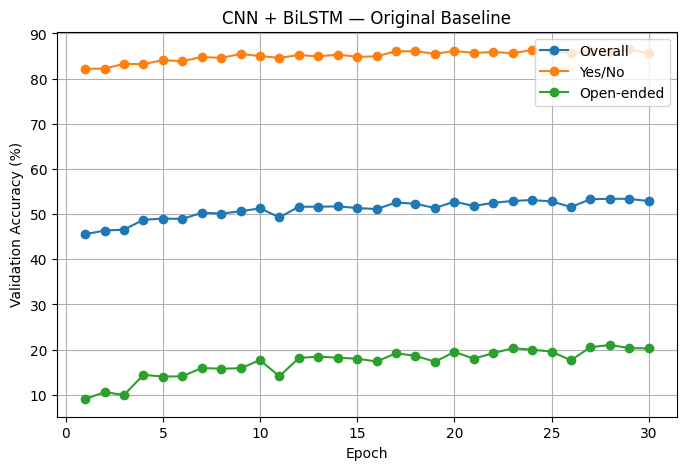

In [39]:
# Visualize original-training accuracy and loss across epochs.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
for col, label in [
    ("overall_accuracy", "Overall"),
    ("yes_no_accuracy", "Yes/No"),
    ("open_accuracy", "Open-ended"),
]:
    plt.plot(results_df["epoch"], results_df[col] * 100, marker="o", label=label)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("CNN + BiLSTM — Original Baseline")
plt.legend()
plt.grid(True)
plt.show()

## 10. FINE-TUNING EXPERIMENT — Resume Best Model at Lower Learning Rate

This is a **separate experiment**. It starts from the original best checkpoint, not random weights. The original checkpoint is never overwritten. Fine-tuning uses learning rate 0.0001, up to 10 epochs, patience 3.

In [40]:
# Resume from the best model with a reduced fine-tuning learning rate.
import torch.optim as optim

# Section 9 loaded the best baseline weights into `model`.
# Reload to guarantee this experiment starts from the original best model.
model.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
model.to(device)

optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)
print("Ready to fine-tune from:", best_model_path)

Ready to fine-tune from: /kaggle/working/best_late_fusion.pth


In [41]:
# Fine-tune with validation-based checkpoint selection and early stopping.
import copy

# Validation returns fractions (e.g. 0.5295), not percentages.
baseline_accuracy = best_val_metrics["overall_accuracy"]
best_finetune_accuracy = baseline_accuracy
best_finetune_state = copy.deepcopy(model.state_dict())
no_improvement = 0
patience = 3
finetune_history = []
best_finetune_epoch = 0

for epoch in range(1, 11):
    train_loss = train_one_epoch(model, train_loader, optimizer, device)
    metrics = validate(model, val_loader, device)

    overall = metrics["overall_accuracy"]
    yes_no = metrics["closed_accuracy"]
    open_acc = metrics["open_accuracy"]

    finetune_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "overall_accuracy": overall,
        "yes_no_accuracy": yes_no,
        "open_accuracy": open_acc,
    })
    print(
        f"Fine-tune epoch {epoch:02d} | Loss: {train_loss:.4f} | "
        f"Overall: {overall:.2%} | Yes/No: {yes_no:.2%} | Open: {open_acc:.2%}"
    )

    if overall > best_finetune_accuracy:
        best_finetune_accuracy = overall
        best_finetune_epoch = epoch
        best_finetune_state = copy.deepcopy(model.state_dict())
        no_improvement = 0
        torch.save(best_finetune_state, "/kaggle/working/best_late_fusion_finetuned.pth")
        print("Improved fine-tuned checkpoint saved.")
    else:
        no_improvement += 1

    if no_improvement >= patience:
        print("Fine-tuning early stopping triggered.")
        break

print(f"Original overall accuracy: {baseline_accuracy:.2%}")
print(f"Best fine-tuned overall accuracy: {best_finetune_accuracy:.2%}")
if best_finetune_epoch == 0:
    print("No overall accuracy improvement; keep the original checkpoint.")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child processException ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Fine-tune epoch 01 | Loss: 0.9371 | Overall: 54.02% | Yes/No: 86.18% | Open: 21.95%
Improved fine-tuned checkpoint saved.


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (26 outputs left out)

if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Fine-tune epoch 07 | Loss: 0.8479 | Overall: 54.18% | Yes/No: 86.37% | Open: 22.08%
Fine-tuning early stopping triggered.
Original overall accuracy: 53.40%
Best fine-tuned overall accuracy: 54.42%


In [42]:
# Summarize fine-tuning history for comparison with original training.

import pandas as pd

finetune_df = pd.DataFrame(finetune_history)

finetune_df.to_csv(
    "/kaggle/working/late_fusion_finetune_history.csv",
    index=False
)

display(finetune_df)


,epoch,train_loss,overall_accuracy,yes_no_accuracy,open_accuracy
0,1,0.937130,0.540182,0.86176,0.219528
1,2,0.898993,0.541460,0.86048,0.223357
2,3,0.884149,0.543857,0.86176,0.226867
3,4,0.868581,0.544176,0.86432,0.224952
4,5,0.864825,0.543058,0.86304,0.223995
5,6,0.862308,0.541620,0.86112,0.223038
6,7,0.847894,0.541780,0.86368,0.220804


## 11. Compare Original vs Fine-Tuned Model

Compare validation metrics using the best fine-tuned weights if an improvement was saved.

In [43]:
# Locate fine-tuned artifacts for final reporting.
import os

fine_path = "/kaggle/working/best_late_fusion_finetuned.pth"
if os.path.exists(fine_path):
    model.load_state_dict(torch.load(fine_path, map_location=device, weights_only=True))
    fine_metrics = validate(model, val_loader, device)
else:
    fine_metrics = best_val_metrics
    print("No improved checkpoint was saved; original baseline remains best.")

comparison = pd.DataFrame([
    {"model": "Original baseline", **best_val_metrics},
    {"model": "Fine-tuned (best overall)", **fine_metrics},
])
display(comparison.style.format({
    "overall_accuracy": "{:.2%}",
    "closed_accuracy": "{:.2%}",
    "open_accuracy": "{:.2%}",
}))
comparison.to_csv("/kaggle/working/late_fusion_comparison.csv", index=False)

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/p

,model,overall_accuracy,closed_accuracy,open_accuracy
0,Original baseline,53.40%,85.86%,21.03%
1,Fine-tuned (best overall),54.42%,86.43%,22.50%


### Exploratory 2,000-answer experiment: interpretation

This section rebuilds only the open-answer label space to include up to 2,000 frequent training answers, creates a corresponding dataset and initializes a separate model. It is **not** the model used for the main nine-model comparison, which consistently uses 1,000 open-answer classes. Any difference between the two runs should be treated as an exploratory observation, not as a controlled estimate of vocabulary-size effects across random seeds.

## 12. Experiment 2 — 2,000 Open-Ended Answer Classes

**Purpose:** Test whether increasing the output vocabulary from 1,000 to 2,000 improves open-ended accuracy. This is a **new model trained from random initialization**, not fine-tuning of the 1,000-class checkpoint.

- Same cleaned splits, image preprocessing, question vocabulary, CNN, BiLSTM, batch size and optimizer settings.
- Only the open-ended answer vocabulary and output head size change.
- The original `open_answer2idx`, `model`, and checkpoints remain unchanged.
- Expected validation answer coverage from your experiment: **2,171 / 3,134 = 69.27%**.
- **Skip the training cell when restoring an existing 2,000-class checkpoint.**

In [44]:
# Construct the separate exploratory 2,000-class open-answer mapping.
from collections import Counter

OPEN_VOCAB_SIZE_2000 = 2000

open_answer_counts_2000 = Counter(
    str(a).lower().strip()
    for a in clean_train["answer"]
    if str(a).lower().strip() not in ("yes", "no")
)

top_open_answers_2000 = [
    answer for answer, count
    in open_answer_counts_2000.most_common(OPEN_VOCAB_SIZE_2000)
]
open_answer2idx_2000 = {
    answer: idx for idx, answer in enumerate(top_open_answers_2000)
}

def encode_answer_2000(answer):
    answer = str(answer).lower().strip()
    if answer == "no":
        return 0, 0
    if answer == "yes":
        return 0, 1
    return 1, open_answer2idx_2000.get(answer, -1)

print("Open answer classes:", len(open_answer2idx_2000))
print("Yes:", encode_answer_2000("yes"))
print("No:", encode_answer_2000("no"))
print("Open:", encode_answer_2000(top_open_answers_2000[0]))

Open answer classes: 2000
Yes: (0, 1)
No: (0, 0)
Open: (1, 0)


In [45]:
# Check how many training open answers the expanded mapping covers.
total_open_2000 = 0
covered_open_2000 = 0
for example in clean_val:
    answer_type, label = encode_answer_2000(example["answer"])
    if answer_type == 1:
        total_open_2000 += 1
        covered_open_2000 += (label >= 0)

print("Open-ended validation questions:", total_open_2000)
print("Covered answers:", covered_open_2000)
print(f"Validation coverage: {covered_open_2000 / total_open_2000:.2%}")

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Open-ended validation questions: 3134
Covered answers: 2171
Validation coverage: 69.27%


In [46]:
# Create a dataset and loaders using the exploratory answer mapping.
from torch.utils.data import Dataset, DataLoader

class PathVQADataset2000(Dataset):
    def __init__(self, hf_dataset):
        self.data = hf_dataset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]
        answer_type, answer_label = encode_answer_2000(sample["answer"])
        return {
            "image": preprocess_image(sample["image"]),
            "question": torch.tensor(encode_question(sample["question"]), dtype=torch.long),
            "answer_type": torch.tensor(answer_type, dtype=torch.long),
            "answer_label": torch.tensor(answer_label, dtype=torch.long),
        }

train_dataset_2000 = PathVQADataset2000(clean_train)
val_dataset_2000 = PathVQADataset2000(clean_val)

train_loader_2000 = DataLoader(
    train_dataset_2000, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
val_loader_2000 = DataLoader(
    val_dataset_2000, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

print("Training samples:", len(train_dataset_2000))
print("Validation samples:", len(val_dataset_2000))
print("Training batches:", len(train_loader_2000))
print("Validation batches:", len(val_loader_2000))

Training samples: 19648
Validation samples: 6259
Training batches: 614
Validation batches: 196


In [47]:
# Initialize a new model with the expanded open-answer output dimension.
model_2000 = LateFusionVQA(
    vocab_size=len(word2idx),
    num_open_answers=len(open_answer2idx_2000)
).to(device)

optimizer_2000 = torch.optim.Adam(
    model_2000.parameters(), lr=0.001, weight_decay=1e-5
)

print("Open output classes:", model_2000.open_head.out_features)
print("Total parameters:", sum(p.numel() for p in model_2000.parameters()))
print("Optimizer ready.")

Open output classes: 2000
Total parameters: 1873618
Optimizer ready.


### 12.1 Train 2,000-class model — up to 30 epochs

**Run only for a fresh 2,000-class training experiment.** Saves best weights, resumable latest checkpoint, and CSV history using distinct filenames.

In [48]:
# Train and validate the exploratory 2,000-answer experiment separately.
import os
import pandas as pd

MAX_EPOCHS_2000 = 30
PATIENCE_2000 = 5
best_accuracy_2000 = -1.0
best_epoch_2000 = 0
no_improvement_2000 = 0
history_2000 = []

best_path_2000 = "/kaggle/working/best_late_fusion_2000.pth"
latest_path_2000 = "/kaggle/working/late_fusion_2000_latest.pth"

for epoch in range(1, MAX_EPOCHS_2000 + 1):
    train_loss = train_one_epoch(model_2000, train_loader_2000, optimizer_2000, device)
    metrics = validate(model_2000, val_loader_2000, device)

    overall = metrics["overall_accuracy"]
    yes_no = metrics["closed_accuracy"]
    open_acc = metrics["open_accuracy"]

    history_2000.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "overall_accuracy": overall,
        "yes_no_accuracy": yes_no,
        "open_accuracy": open_acc,
    })

    print(
        f"Epoch {epoch:02d} | Loss: {train_loss:.4f} | "
        f"Overall: {overall:.2%} | Yes/No: {yes_no:.2%} | Open: {open_acc:.2%}"
    )

    if overall > best_accuracy_2000:
        best_accuracy_2000 = overall
        best_epoch_2000 = epoch
        no_improvement_2000 = 0
        torch.save(model_2000.state_dict(), best_path_2000)
        print("New best model saved!")
    else:
        no_improvement_2000 += 1

    torch.save({
        "epoch": epoch,
        "model_state_dict": model_2000.state_dict(),
        "optimizer_state_dict": optimizer_2000.state_dict(),
        "history": history_2000,
        "best_accuracy": best_accuracy_2000,
        "best_epoch": best_epoch_2000,
        "word2idx": word2idx,
        "open_answer2idx": open_answer2idx_2000,
    }, latest_path_2000)

    pd.DataFrame(history_2000).to_csv(
        "/kaggle/working/late_fusion_2000_history.csv", index=False
    )

    if no_improvement_2000 >= PATIENCE_2000:
        print("Early stopping triggered.")
        break

print("Best epoch:", best_epoch_2000)
print(f"Best validation accuracy: {best_accuracy_2000:.2%}")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 01 | Loss: 2.8889 | Overall: 45.68% | Yes/No: 82.08% | Open: 9.38%
New best model saved!


Training:   0%|          | 0/614 [00:00<?, ?it/s]

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

... (105 outputs left out)

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac3ddf29d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Epoch 30 | Loss: 1.0709 | Overall: 53.51% | Yes/No: 85.57% | Open: 21.54%
New best model saved!
Best epoch: 30
Best validation accuracy: 53.51%


### 12.2 Load and evaluate best 2,000-class checkpoint

This cell works after training **or** after adding your previous checkpoint as a Kaggle Input. It does not retrain the model.

In [49]:
# Collect output artifacts for archiving or downloading.
import glob

candidates_2000 = (
    glob.glob("/kaggle/working/best_late_fusion_2000.pth") +
    glob.glob("/kaggle/input/**/best_late_fusion_2000.pth", recursive=True)
)
if not candidates_2000:
    raise FileNotFoundError("Upload best_late_fusion_2000.pth as Kaggle Input.")

best_model_path_2000 = candidates_2000[0]
model_2000.load_state_dict(
    torch.load(best_model_path_2000, map_location=device, weights_only=True)
)
model_2000.eval()

best_metrics_2000 = validate(model_2000, val_loader_2000, device)
print("BEST 2,000-ANSWER MODEL RESULTS")
print(f"Overall accuracy: {best_metrics_2000['overall_accuracy']:.2%}")
print(f"Yes/No accuracy: {best_metrics_2000['closed_accuracy']:.2%}")
print(f"Open-ended accuracy: {best_metrics_2000['open_accuracy']:.2%}")
print("Checkpoint:", best_model_path_2000)

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

BEST 2,000-ANSWER MODEL RESULTS
Overall accuracy: 53.51%
Yes/No accuracy: 85.57%
Open-ended accuracy: 21.54%
Checkpoint: /kaggle/working/best_late_fusion_2000.pth


## 13. Results Summary — Recorded Experiments

These are the **results you reported** from your Kaggle runs, not outputs produced by this organized notebook. Re-running experiments may produce slightly different results.

| Experiment | Best epoch | Overall | Yes/No | Open-ended |
|---|---:|---:|---:|---:|
| Original CNN + BiLSTM (1,000 answers) | 20 | 52.95% | 86.14% | 19.85% |
| Fine-tuned CNN + BiLSTM (1,000 answers) | 4 extra | **54.26%** | **86.24%** | **22.37%** |
| CNN + BiLSTM (2,000 answers) | 21 | 52.63% | 85.89% | 19.46% |

**Interpretation:** Fine-tuning the 1,000-answer model yielded the highest observed validation accuracy. The 2,000-answer model covered more answers but did not improve observed accuracy. The 2,000-class run did not receive the additional fine-tuning, so it is not a perfectly matched fine-tuning comparison.

**Evaluation caveat:** The validation code uses the ground-truth answer type to choose the yes/no or open-ended prediction head. Report this as oracle answer-type routing unless you implement a question-based type router.


### Outputs and reproducibility checklist

After a completed run, retain the notebook (`.ipynb`) with its displayed training curves and outputs, original and fine-tuned best checkpoints, vocabulary-bearing checkpoint, and history CSVs. Record the Kaggle runtime/GPU, installed library versions and the exact attached dataset versions. Re-running training may not reproduce identical best-epoch values because GPU execution and software versions can vary.

**Submission distinction:** this notebook demonstrates training and validation; final test metrics, predicted-routing evaluation, open-answer token F1/BLEU and paired statistical tests are documented separately in the all-model evaluation notebook and reliability report. Do not interpret the original-versus-fine-tuned plots as held-out test performance.

## 14. Save and Download Checkpoints and History

Check which outputs are available, then create a ZIP in `/kaggle/working`. The ZIP is assembled outside the working directory to prevent self-inclusion.

In [50]:
# List generated experiment files before packaging.
import os
for name in [
    "best_late_fusion.pth",
    "late_fusion_latest.pth",
    "late_fusion_history.csv",
    "best_late_fusion_finetuned.pth",
    "late_fusion_finetune_history.csv",
    "best_late_fusion_2000.pth",
    "late_fusion_2000_latest.pth",
    "late_fusion_2000_history.csv",
]:
    print(f"{name}: {'FOUND' if os.path.exists('/kaggle/working/' + name) else 'NOT IN WORKING'}")

best_late_fusion.pth: FOUND
late_fusion_latest.pth: FOUND
late_fusion_history.csv: FOUND
best_late_fusion_finetuned.pth: FOUND
late_fusion_finetune_history.csv: FOUND
best_late_fusion_2000.pth: FOUND
late_fusion_2000_latest.pth: FOUND
late_fusion_2000_history.csv: FOUND


In [51]:
# Package saved outputs; this cell does not change model parameters.
!rm -f /kaggle/working/pathvqa_all_experiments.zip
!cd /kaggle/working && zip -r /kaggle/pathvqa_all_experiments.zip . -x '*.zip'
!mv /kaggle/pathvqa_all_experiments.zip /kaggle/working/pathvqa_all_experiments.zip
!ls -lh /kaggle/working/pathvqa_all_experiments.zip

  adding: late_fusion_2000_history.csv (deflated 51%)
  adding: best_late_fusion_finetuned.pth (deflated 7%)
  adding: best_late_fusion_2000.pth (deflated 7%)
  adding: late_fusion_finetune_history.csv (deflated 46%)
  adding: late_fusion_latest.pth (deflated 7%)
  adding: late_fusion_2000_latest.pth (deflated 7%)
  adding: .virtual_documents/ (stored 0%)
  adding: .virtual_documents/__notebook_source__.ipynb (deflated 75%)
  adding: best_late_fusion.pth (deflated 6%)
  adding: late_fusion_history.csv (deflated 51%)
  adding: late_fusion_comparison.csv (deflated 24%)
-rw-r--r-- 1 root root 56M Nov  3 13:55 /kaggle/working/pathvqa_all_experiments.zip
